In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import os
import seaborn as sns

In [2]:
from analysis import small_label_settings, large_label_settings
plt.style.use('default')
plt.rcParams.update(small_label_settings)

There are 3 real clones that have < 2 observation times.


In [3]:
# Load data
# experiment = '12.09.2025_04.29_PM'
# file = f'./sperm-data-analysis/experiments/{experiment}/final_data.csv'
file = os.path.join('..', 'experiments', 'full_pipeline', 'final_data.csv') 
df = pd.read_csv(file)

In [4]:
# Filter for sample 1 and exclude fishwater
df_filtered = df[(df['sample'] == 1) & (~df['fish'].str.contains("fishwater", case=False))]

In [5]:
# Define the unedited barcode
none_barcode = "NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE"

In [6]:
# Average proportions across replicates for each fish-barcode combination
PROPORTION_COL = 'proportion'

barcode_props = (
    df_filtered.groupby(['fish', 'barcode'])[PROPORTION_COL]
    .mean()
    .reset_index()
)

# Renormalize so proportions sum to 1.0 for each fish
barcode_props['proportion'] = (
    barcode_props.groupby('fish')['proportion']
    .transform(lambda x: x / x.sum())
)

In [7]:
# Pivot to get barcodes as columns
pivot_df = barcode_props.pivot(index='fish', columns='barcode', values=PROPORTION_COL).fillna(0)

In [8]:
# Collapse replicates: count unique barcodes per fish across all replicates
barcode_counts = (
    df.groupby('fish')['barcode']
    .nunique()
    .reset_index(name='unique_barcode_count')
)

In [9]:
# Sort fish: numerical order first, then 'fishctrl' at the bottom
def sort_fish(fish_name):
    fish_str = str(fish_name).lower()
    if 'ctrl' in fish_str or 'control' in fish_str:
        return (1, fish_str)
    else:
        # Try to extract number from fish name
        import re
        numbers = re.findall(r'\d+', fish_str)
        if numbers:
            return (0, int(numbers[0]))  
        else:
            return (0, fish_str)

fish_list = sorted(pivot_df.index.tolist(), key=sort_fish)
pivot_df = pivot_df.loc[fish_list]
n_fish = len(fish_list)

In [10]:
# Define the base color palette by barcode rank (most abundant → least)
rank_colors = [
    "#ff4d6f", "#579ea4", "#df7713", "#f9c000", "#86ad34",
    "#5d7298", "#81b28d", "#7e1a2f", "#2d2651", "#c8350d", "#bd777a"
]

# If more than 11 barcodes per fish, extend palette
extra_colors = ['#1a5f7a', '#C86BCE', '#75B6FF', '#F9FD7F', '#006400', '#FFC4DE',
                '#FA8072', '#D8FC74', '#571B64', '#00b4d8', '#CA2A6F'
]

# Combine base + extra so it's long enough for all cases
extended_colors = rank_colors + extra_colors

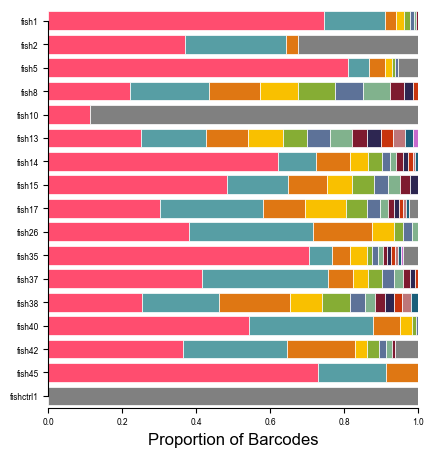


Plot created for 17 fish (rank-based colors)
Total unique barcodes across all fish: 134


In [11]:
# Figure 1E: Create the stacked horizontal bar plot
fig, ax = plt.subplots(figsize=(4.35, max(4, n_fish * 0.27)))

# Reverse so controls appear at bottom
fish_list_reversed = fish_list[::-1]

for i, fish in enumerate(fish_list_reversed):
    fish_data = pivot_df.loc[fish]
    fish_data = fish_data[fish_data > 0].sort_values(ascending=False)

    # Separate NONE barcode
    none_prop = fish_data.get(none_barcode, 0)
    other_barcodes = fish_data.drop(none_barcode, errors='ignore')

    # Assign colors by rank (most → least abundant)
    n_barcodes = len(other_barcodes)
    colors = [extended_colors[j % len(extended_colors)] for j in range(n_barcodes)]

    # Plot bars
    left = 0
    for j, (barcode, prop) in enumerate(other_barcodes.items()):
        ax.barh(i, prop, left=left, height=0.8,
                color=colors[j], edgecolor='white', linewidth=0.5)
        left += prop

    # Plot NONE barcode last (gray)
    if none_prop > 0:
        ax.barh(i, none_prop, left=left, height=0.8,
                color='gray', edgecolor='white', linewidth=0.5)

#  Formatting
ax.set_yticks(range(n_fish))
ax.set_yticklabels(fish_list_reversed)
ax.set_xlabel('Proportion of Barcodes', fontsize=12)
ax.set_xlim(0, 1)
ax.set_ylim(-0.5, n_fish - 0.5)
sns.despine(trim=True)

# Legend for NONE barcode (optional)
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(loc='upper right', frameon=False)

plt.tight_layout()

# Save high-quality versions
#plt.savefig("barcode_proportions_by_fish_ranked_colors_v3.svg", bbox_inches='tight', transparent=True)
#plt.savefig("barcode_proportions_by_fish_ranked_colors_v3.png", dpi=600, bbox_inches='tight', transparent=True)

plt.show()

print(f"\nPlot created for {n_fish} fish (rank-based colors)")
print(f"Total unique barcodes across all fish: {len(pivot_df.columns)}")

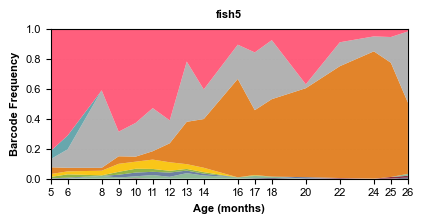

In [12]:
# Specify which fish to plot
fish_id = 'fish5'  # Change this to your specific fish ID

# Define your custom color palette
custom_colors = ["#ff4d6f", "#579ea4", "#df7713", "#f9c000", "#86ad34",
              "#5d7298", "#81b28d", "#7e1a2f", "#2d2651", "#c8350d", "#bd777a",
              '#1a5f7a', '#C86BCE', '#75B6FF', '#F9FD7F', '#006400', '#FFC4DE',
              '#FA8072', '#D8FC74', '#571B64', '#00b4d8', '#CA2A6F']

# Sample map - maps sample numbers to fish age in months
sample_map = {
    1: 5, 
    2: 6, 
    3: 7, 
    4: 8, 
    5: 9, 
    6: 10, 
    7: 11, 
    8: 12, 
    9: 13, 
    10: 14, 
    11: 16, 
    12: 17, 
    13: 18, 
    14: 20, 
    15: 22, 
    16: 24, 
    17: 25, 
    18: 26
}

# Filter dataset for the specific fish
fish_data = df[df['fish'] == fish_id].copy()

# Sort the RAW data (before grouping) by sample and reads - THIS IS THE KEY
# This matches: sorted_data = subset.sort_values(by=['sample', 'reads'], ascending=[True, False])
sorted_data = fish_data.sort_values(by=['sample', 'reads'], ascending=[True, False])

# Get barcode order from the sorted raw data
# This matches: barcode_order = sorted_data['barcode'].unique()
barcode_order = sorted_data['barcode'].unique()

# NOW group by sample and barcode to sum reads across replicates
grouped = (
    fish_data.groupby(['barcode', 'sample'], as_index=False)
    .agg({'reads': 'sum'})
)

# Pivot to get barcodes as rows and samples as columns
pivot_data = grouped.pivot(index='barcode', columns='sample', values='reads')

# Fill any missing values with 0
pivot_data = pivot_data.fillna(0)

# Reorder rows to match barcode_order
pivot_data = pivot_data.loc[barcode_order]

# Convert to numpy array for processing
obs_data = pivot_data.values

# Convert reads to frequencies by dividing by column sums
freq_data = obs_data / np.sum(obs_data, axis=0)

# Convert barcode_order to pandas Index for compatibility
barcode_order = pd.Index(barcode_order)

# Extract timepoints (sample numbers)
times = np.array(pivot_data.columns)

# Map samples to actual ages if needed
map_samples = True  # Set to False to use sample numbers instead
if map_samples:
    times_display = np.array([sample_map[t] for t in times])
else:
    times_display = times

# Prepare colors
n_barcodes = freq_data.shape[0]
repeats = -(-n_barcodes // len(custom_colors))  # Round up division
colors_extended = np.tile(custom_colors, repeats)[:n_barcodes]

# Mark unedited barcode with grey color
unedited_barcode = 'NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE'
unedited_index = None
if unedited_barcode in barcode_order:
    unedited_index = barcode_order.get_loc(unedited_barcode)
    # Insert grey at the unedited position
    colors_extended = np.insert(colors_extended, unedited_index, '#aaaaaa')
    # Remove last element to maintain correct length
    colors_extended = colors_extended[:-1]

# Create figure with custom size
fig, ax = plt.subplots(figsize=(4.25, 2.25))

# Create the stacked area plot (Muller plot)
ax.stackplot(times_display, *freq_data[::-1, :], colors=colors_extended[::-1], alpha=0.9)

# Optional: Add legend showing barcode-color mapping
add_legend = False  # Set to False to hide legend

if add_legend:
    from matplotlib.patches import Patch
    
    # Create legend handles (NOT reversed - matches barcode_order)
    handles = [Patch(facecolor=c, label=b) for c, b in zip(colors_extended, barcode_order)]
    
    # Add legend - customize as needed
    ax.legend(handles=handles[:20],  # Show only top 20 barcodes
              title="Barcode", 
              bbox_to_anchor=(1.05, 1), 
              loc='upper left',
              fontsize=6,
              title_fontsize=6,
              frameon=True)

# Customize axes labels
ax.set_xlabel('Age (months)', fontsize=8, fontweight='bold', fontfamily='Arial')
ax.set_ylabel('Barcode Frequency', fontsize=8, fontweight='bold', fontfamily='Arial')
ax.set_title(f'{fish_id}', fontsize=8, fontweight='bold', fontfamily='Arial', pad=8)

# Set x-axis ticks
ax.set_xticks(times_display)
ax.set_xticklabels([f'{int(t)}' for t in times_display], fontsize=8, fontfamily='Arial')

# Customize y-axis
ax.set_ylim(0, 1)
ax.set_xlim(times_display[0], times_display[-1])
ax.tick_params(axis='y', labelsize=8)
for label in ax.get_yticklabels():
    label.set_fontfamily('Arial')

# Add grid for better readability (optional)
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
ax.set_axisbelow(True)

# Adjust layout to prevent legend cutoff
plt.tight_layout()

# Optional: Save the plot
#plt.savefig(f'./experiments/{experiment}/muller_{fish_id}_averaged_v3.svg', bbox_inches='tight', transparent=True)
#plt.savefig(f'./experiments/{experiment}/muller_{fish_id}_averaged_v3.png', dpi=300, bbox_inches='tight')

# Display the plot
plt.show()

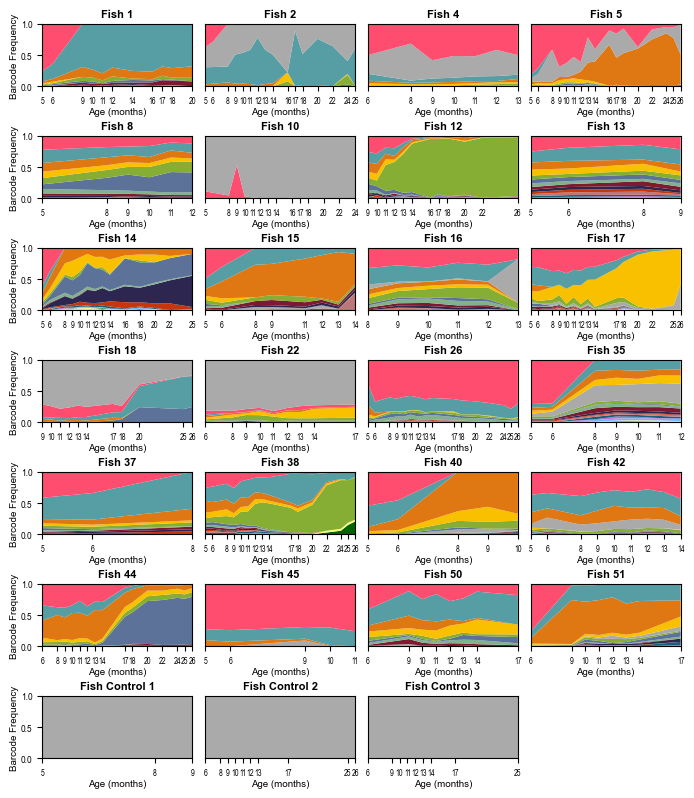

In [13]:
# List of fish to plot
fish_list = ['fish1', 'fish2', 'fish4', 'fish5', 'fish8', 'fish10',
            'fish12', 'fish13', 'fish14', 'fish15', 'fish16', 'fish17',
            'fish18', 'fish22', 'fish26', 'fish35', 'fish37', 'fish38',
            'fish40', 'fish42', 'fish44', 'fish45', 'fish50', 
             'fish51', 'fishctrl1', 'fishctrl2', 'fishctrl3'
            ]

# Define your custom color palette
custom_colors = ["#ff4d6f", "#579ea4", "#df7713", "#f9c000", "#86ad34",
              "#5d7298", "#81b28d", "#7e1a2f", "#2d2651", "#c8350d", "#bd777a",
              '#1a5f7a', '#C86BCE', '#75B6FF', '#F9FD7F', '#006400', '#FFC4DE',
              '#FA8072', '#D8FC74', '#571B64', '#00b4d8', '#CA2A6F']

# Sample map - maps sample numbers to fish age in months
sample_map = {
    1: 5, 2: 6, 3: 7, 4: 8, 5: 9, 6: 10, 7: 11, 8: 12, 9: 13, 10: 14,
    11: 16, 12: 17, 13: 18, 14: 20, 15: 22, 16: 24, 17: 25, 18: 26
}

# Determine grid layout
n_fish = len(fish_list)
n_cols = 4  # Number of columns in the grid
n_rows = -(-n_fish // n_cols)  # Ceiling division

# Create figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7, 8))

# Flatten axes array for easier iteration
if n_fish == 1:
    axes = np.array([axes])
else:
    axes = axes.flatten()

# Mark unedited barcode
unedited_barcode = 'NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE'

# Plot each fish
for idx, fish_id in enumerate(fish_list):
    ax = axes[idx]
    
    # Filter dataset for the specific fish
    fish_data = df[df['fish'] == fish_id].copy()
    
    # Sort the RAW data by sample and reads
    sorted_data = fish_data.sort_values(by=['sample', 'reads'], ascending=[True, False])
    
    # Get barcode order from the sorted raw data
    barcode_order = sorted_data['barcode'].unique()
    
    # Group by sample and barcode to sum reads across replicates
    grouped = (
        fish_data.groupby(['barcode', 'sample'], as_index=False)
        .agg({'reads': 'sum'})
    )
    
    # Pivot to get barcodes as rows and samples as columns
    pivot_data = grouped.pivot(index='barcode', columns='sample', values='reads')
    pivot_data = pivot_data.fillna(0)
    
    # Reorder rows to match barcode_order
    pivot_data = pivot_data.loc[barcode_order]
    
    # Convert to numpy array
    obs_data = pivot_data.values
    
    # Convert reads to frequencies
    freq_data = obs_data / np.sum(obs_data, axis=0)
    
    # Convert barcode_order to pandas Index
    barcode_order = pd.Index(barcode_order)
    
    # Extract and map timepoints
    times = np.array(pivot_data.columns)
    times_display = np.array([sample_map[t] for t in times])
    
    # Prepare colors
    n_barcodes = freq_data.shape[0]
    repeats = -(-n_barcodes // len(custom_colors))
    colors_extended = np.tile(custom_colors, repeats)[:n_barcodes]
    
    # Mark unedited barcode with grey
    if unedited_barcode in barcode_order:
        unedited_index = barcode_order.get_loc(unedited_barcode)
        colors_extended = np.insert(colors_extended, unedited_index, '#aaaaaa')
        colors_extended = colors_extended[:-1]
    
    # Create stacked area plot
    ax.stackplot(times_display, *freq_data[::-1, :], colors=colors_extended[::-1])
    
    # Customize axes
    ax.set_xlabel('Age (months)', fontsize=7, fontfamily='Arial')
    if idx % n_cols == 0:
        ax.set_ylabel('Barcode Frequency', fontsize=7, fontfamily='Arial')
    else:
        ax.set_yticks([])
    ax.xaxis.labelpad = 1.5
    ax.yaxis.labelpad = 1.5
    
    title = fish_id.replace('fish', 'Fish ').replace('ctrl', 'Control ')
    ax.set_title(title, fontsize=8, fontweight='bold', fontfamily='Arial', pad=5)
    
    # Set ticks
    ax.set_xticks(times_display)
    ax.set_xticklabels([f'{int(t)}' for t in times_display], fontsize=6, fontfamily='Arial')
    
    # Customize y-axis
    ax.set_ylim(0, 1)
    ax.set_xlim(times_display[0], times_display[-1])
    # ax.tick_params(axis='y', labelsize=6)
    # ax.tick_params(axis='both', labelsize=6)
    for label in ax.get_xticklabels():
        label.set_fontname('Arial Narrow')
    
    # Add grid
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
    ax.set_axisbelow(True)

# Hide any unused subplots
for idx in range(n_fish, len(axes)):
    axes[idx].set_visible(False)

# Adjust layout
plt.tight_layout(h_pad=0.5, w_pad=0.75)

# Save the plot
plt.savefig(os.path.join('images', 'muller_faceted_all_fish.svg'), bbox_inches='tight', transparent=True)
plt.savefig(os.path.join('images', 'muller_faceted_all_fish.png'), dpi=300, bbox_inches='tight')

# Display
plt.show()

In [14]:
# Poster plot

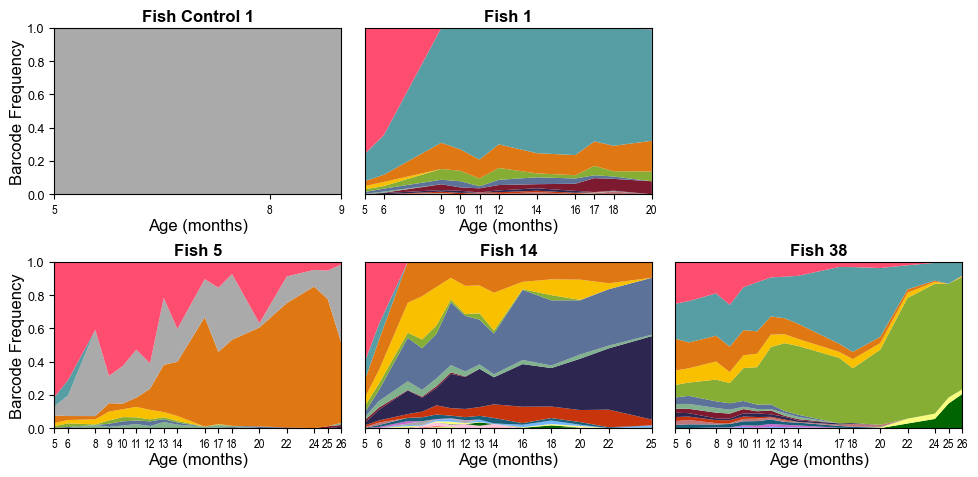

In [36]:
# plt.style.use('default')
plt.rcParams.update(large_label_settings)

# List of fish to plot
fish_list = ['fishctrl1', 'fish1', 'fish5', 'fish14', 'fish38']

# Define your custom color palette
custom_colors = ["#ff4d6f", "#579ea4", "#df7713", "#f9c000", "#86ad34",
              "#5d7298", "#81b28d", "#7e1a2f", "#2d2651", "#c8350d", "#bd777a",
              '#1a5f7a', '#C86BCE', '#75B6FF', '#F9FD7F', '#006400', '#FFC4DE',
              '#FA8072', '#D8FC74', '#571B64', '#00b4d8', '#CA2A6F']

# Sample map - maps sample numbers to fish age in months
sample_map = {
    1: 5, 2: 6, 3: 7, 4: 8, 5: 9, 6: 10, 7: 11, 8: 12, 9: 13, 10: 14,
    11: 16, 12: 17, 13: 18, 14: 20, 15: 22, 16: 24, 17: 25, 18: 26
}

# Determine grid layout
n_fish = 6
n_cols = 3  # Number of columns in the grid
n_rows = 2

# Create figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 5))

# Flatten axes array for easier iteration
if n_fish == 1:
    axes = np.array([axes])
else:
    axes = axes.flatten()

# Mark unedited barcode
unedited_barcode = 'NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE'

# Plot each fish
for idx, fish_id in enumerate(fish_list):
    if idx < 2:
        ax = axes[idx]
    else:
        ax = axes[idx + 1]
    
    # Filter dataset for the specific fish
    fish_data = df[df['fish'] == fish_id].copy()
    
    # Sort the RAW data by sample and reads
    sorted_data = fish_data.sort_values(by=['sample', 'reads'], ascending=[True, False])
    
    # Get barcode order from the sorted raw data
    barcode_order = sorted_data['barcode'].unique()
    
    # Group by sample and barcode to sum reads across replicates
    grouped = (
        fish_data.groupby(['barcode', 'sample'], as_index=False)
        .agg({'reads': 'sum'})
    )
    
    # Pivot to get barcodes as rows and samples as columns
    pivot_data = grouped.pivot(index='barcode', columns='sample', values='reads')
    pivot_data = pivot_data.fillna(0)
    
    # Reorder rows to match barcode_order
    pivot_data = pivot_data.loc[barcode_order]
    
    # Convert to numpy array
    obs_data = pivot_data.values
    
    # Convert reads to frequencies
    freq_data = obs_data / np.sum(obs_data, axis=0)
    
    # Convert barcode_order to pandas Index
    barcode_order = pd.Index(barcode_order)
    
    # Extract and map timepoints
    times = np.array(pivot_data.columns)
    times_display = np.array([sample_map[t] for t in times])
    
    # Prepare colors
    n_barcodes = freq_data.shape[0]
    repeats = -(-n_barcodes // len(custom_colors))
    colors_extended = np.tile(custom_colors, repeats)[:n_barcodes]
    
    # Mark unedited barcode with grey
    if unedited_barcode in barcode_order:
        unedited_index = barcode_order.get_loc(unedited_barcode)
        colors_extended = np.insert(colors_extended, unedited_index, '#aaaaaa')
        colors_extended = colors_extended[:-1]
    
    # Create stacked area plot
    ax.stackplot(times_display, *freq_data[::-1, :], colors=colors_extended[::-1])
    
    # Customize axes
    ax.set_xlabel('Age (months)', fontfamily='Arial')
    if idx == 0 or idx == 2:
        ax.set_ylabel('Barcode Frequency', fontfamily='Arial')
    else:
        ax.set_yticks([])
    ax.xaxis.labelpad = 1.5
    ax.yaxis.labelpad = 1.5
    
    title = fish_id.replace('fish', 'Fish ').replace('ctrl', 'Control ')
    ax.set_title(title, fontweight='bold', fontfamily='Arial', pad=5)
    
    # Set ticks
    ax.set_xticks(times_display)
    ax.set_xticklabels([f'{int(t)}' for t in times_display], fontfamily='Arial')
    
    # Customize y-axis
    ax.set_ylim(0, 1)
    ax.set_xlim(times_display[0], times_display[-1])
    # ax.tick_params(axis='y', labelsize=6)
    # ax.tick_params(axis='both', labelsize=6)
    for label in ax.get_xticklabels():
        label.set_fontname('Arial Narrow')
    
    # Add grid
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
    ax.set_axisbelow(True)

# Hide any unused subplots
axes[2].set_visible(False)

# Adjust layout
plt.tight_layout(h_pad=0.5, w_pad=0.75)

# Save the plot
plt.savefig(os.path.join('images', 'muller_poster.png'), dpi=600, bbox_inches='tight')

# Display
plt.show()